# Практика: Снижение размерности — PCA, t-SNE и UMAP

## Что вы сделаете
В этом ноутбуке вы:

1. загрузите и исследуете датасет `digits` (рукописные цифры);
2. примените **PCA** как препроцессинг: выберете число компонент по cumulative EVR;
3. проинтерпретируете главные компоненты через **loadings**;
4. обучите классификатор на PCA-признаках и сравните с обучением на исходных признаках;
5. визуализируете структуру данных через **t-SNE** и **UMAP**;
6. сравните 2D-проекции PCA, t-SNE и UMAP: насколько хорошо разделяются классы?

## Датасет
Мы используем `digits` из `sklearn.datasets`:
- 1797 изображений рукописных цифр 0–9;
- каждое изображение — 8×8 пикселей = **64 признака** (интенсивность пикселей);
- задача: 10-классовая классификация.

## Что сдавать
1. Заполненный ноутбук со всем кодом.
2. Краткие выводы в конце:
   - сколько компонент PCA достаточно для сохранения 95% дисперсии?
   - как влияет PCA-препроцессинг на качество классификатора?
   - какой метод визуализации (PCA, t-SNE, UMAP) лучше разделяет классы?

---
## Шаг 1. Загрузка и первичный анализ данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

digits = load_digits()
X = digits.data
y = digits.target

print(f"Форма X: {X.shape}")
print(f"Классы: {np.unique(y)}")
print(f"Признаки: {X.shape[1]} (8x8 пикселей)")

Форма X: (1797, 64)
Классы: [0 1 2 3 4 5 6 7 8 9]
Признаки: 64 (8x8 пикселей)


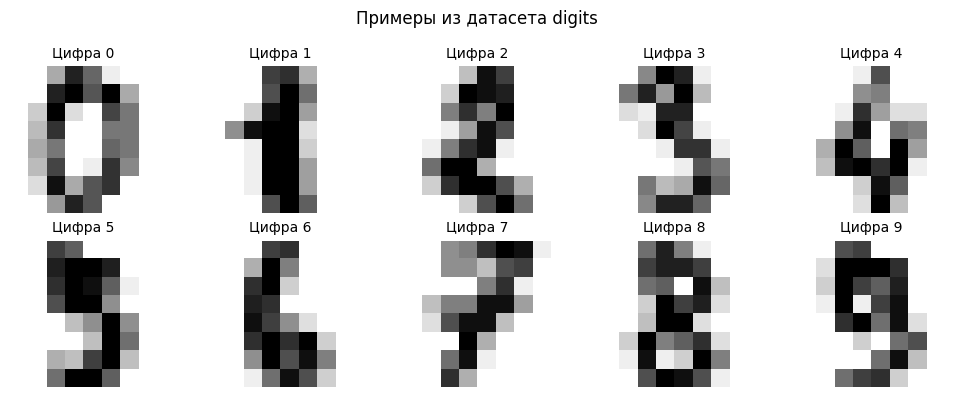

In [ ]:
# Визуализируем примеры из каждого класса
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, range(10)):
    sample_idx = np.where(y == idx)[0][0]
    ax.imshow(X[sample_idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Цифра {idx}', fontsize=10)
    ax.axis('off')
plt.suptitle('Примеры из датасета digits', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Среднее до: {X.mean():.2f}, после: {X_scaled.mean():.4f}")
print(f"Std до: {X.std():.2f}, после: {X_scaled.std():.4f}")

Среднее до: 4.88, после: 0.0000
Std до: 6.02, после: 0.9763


---
## Шаг 2. PCA: explained variance и выбор числа компонент

Обучите PCA на всех 64 компонентах. Постройте график накопленной объясняемой дисперсии.
Определите, сколько компонент нужно для сохранения 80%, 95% и 99% дисперсии.

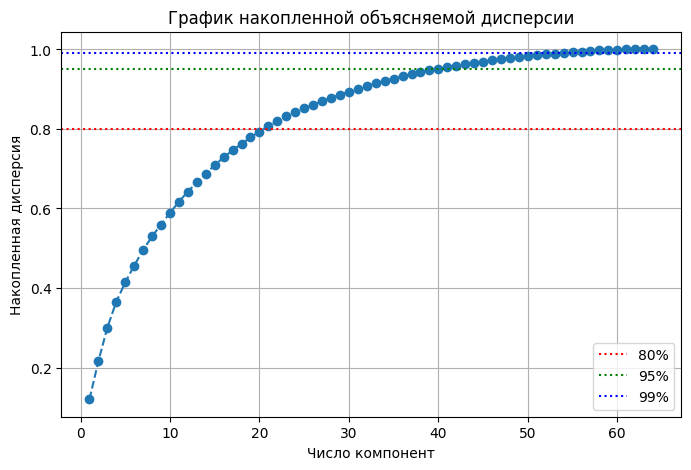

80% дисперсии -> 21 компонент
95% дисперсии -> 40 компонент
99% дисперсии -> 54 компонент


In [ ]:
pca_full = PCA(n_components=64, random_state=42)
pca_full.fit(X_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 65), cumvar, marker='o', linestyle='--')
plt.axhline(y=0.80, color='r', linestyle=':', label='80%')
plt.axhline(y=0.95, color='g', linestyle=':', label='95%')
plt.axhline(y=0.99, color='b', linestyle=':', label='99%')
plt.xlabel('Число компонент')
plt.ylabel('Накопленная дисперсия')
plt.title('График накопленной объясняемой дисперсии')
plt.legend()
plt.grid(True)
plt.show()

for threshold in [0.80, 0.95, 0.99]:
    k = np.argmax(cumvar >= threshold) + 1
    print(f"{int(threshold*100)}% дисперсии -> {k} компонент")

---
## Шаг 3. PCA для визуализации (2 компоненты)

Спроецируйте данные на 2 главных компоненты. Визуализируйте scatter plot с раскраской по классу.
Укажите долю объяснённой дисперсии на осях.

PC1: 12.0%
PC2: 9.6%
Итого: 21.6%


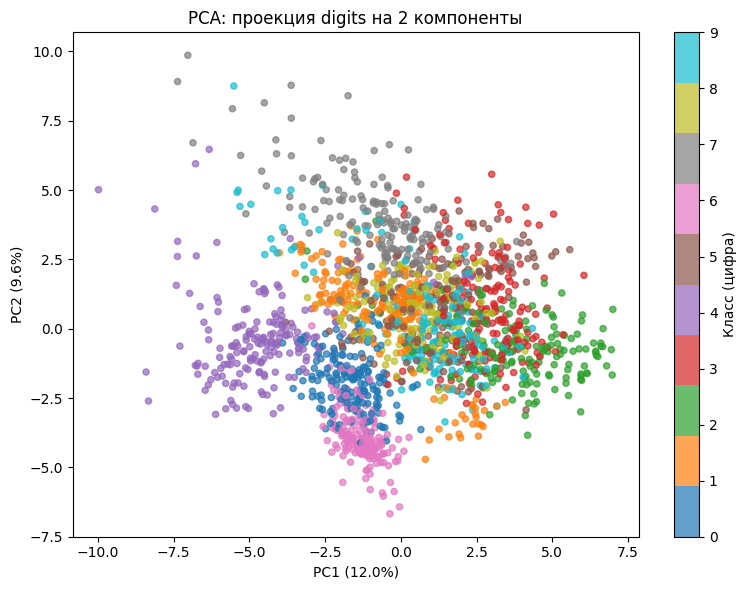

In [ ]:
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_scaled)

print(f"PC1: {pca2.explained_variance_ratio_[0]*100:.1f}%")
print(f"PC2: {pca2.explained_variance_ratio_[1]*100:.1f}%")
print(f"Итого: {pca2.explained_variance_ratio_.sum()*100:.1f}%")

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=y, cmap='tab10', alpha=0.7, s=20)
plt.colorbar(scatter, label='Класс (цифра)')
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA: проекция digits на 2 компоненты')
plt.tight_layout()
plt.show()

---
## Шаг 4. Интерпретация: loadings (нагрузки)

Visualizируйте нагрузки PC1 и PC2 как 8×8 изображения.
Яркие пиксели = сильное влияние на данную компоненту.
Используйте diverging colormap `'RdBu_r'`.

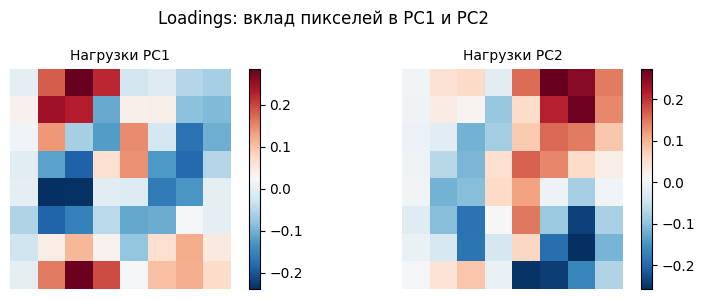

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for i, ax in enumerate(axes):
    im = ax.imshow(pca2.components_[i].reshape(8, 8), cmap='RdBu_r')
    ax.set_title(f'Нагрузки PC{i+1}', fontsize=10)
    ax.axis('off')
    plt.colorbar(im, ax=ax)

plt.suptitle('Loadings: вклад пикселей в PC1 и PC2', fontsize=12)
plt.tight_layout()
plt.show()

# Вопрос: какие области изображения наиболее важны для PC1 и PC2?
# Ответ: Центральные области и края, где обычно проходят линии цифр, имеют наибольший вес (нагрузку).

---
## Шаг 5. PCA как препроцессинг для классификатора

Сравните качество LogisticRegression:
1. На исходных 64 признаках
2. На PCA 95% дисперсии
3. На PCA 80% дисперсии

In [ ]:
import time

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

results = {}

# --- Вариант 1: без PCA ---
start_time = time.time()
clf_base = LogisticRegression(max_iter=1000, random_state=42)
clf_base.fit(X_train, y_train)
duration_base = time.time() - start_time
results['Без PCA (64 признака)'] = (accuracy_score(y_test, clf_base.predict(X_test)), duration_base)

# --- Вариант 2: PCA с 95% дисперсии ---
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_95 = pca_95.fit_transform(X_train)
X_test_95  = pca_95.transform(X_test)

start_time = time.time()
clf_95 = LogisticRegression(max_iter=1000, random_state=42)
clf_95.fit(X_train_95, y_train)
duration_95 = time.time() - start_time
results[f'PCA 95% ({pca_95.n_components_} компонент)'] = (accuracy_score(y_test, clf_95.predict(X_test_95)), duration_95)

# --- Вариант 3: PCA с 80% дисперсии ---
pca_80 = PCA(n_components=0.80, random_state=42)
X_train_80 = pca_80.fit_transform(X_train)
X_test_80  = pca_80.transform(X_test)

start_time = time.time()
clf_80 = LogisticRegression(max_iter=1000, random_state=42)
clf_80.fit(X_train_80, y_train)
duration_80 = time.time() - start_time
results[f'PCA 80% ({pca_80.n_components_} компонент)'] = (accuracy_score(y_test, clf_80.predict(X_test_80)), duration_80)

print(f"{'Метод':<35} | {'Accuracy':<10} | {'Время (сек)':<12}")
print('-' * 65)
for name, (acc, t) in results.items():
    print(f'{name:<35} | {acc:<10.4f} | {t:<12.4f}')

Метод                               | Accuracy   | Время (сек) 
-----------------------------------------------------------------
Без PCA (64 признака)               | 0.9722     | 0.1267      
PCA 95% (40 компонент)              | 0.9639     | 0.3347      
PCA 80% (21 компонент)              | 0.9472     | 0.1348      


---
## Шаг 6. t-SNE: нелинейная визуализация

Рекомендуемый пайплайн: сначала PCA до 30 компонент, затем t-SNE. Это ускоряет работу и убирает шум.

In [ ]:
pca_30 = PCA(n_components=30, random_state=42)
X_pca30 = pca_30.fit_transform(X_scaled)
print(f"После PCA(30): {pca_30.explained_variance_ratio_.sum()*100:.1f}% дисперсии")

tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_pca30)

plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10', s=10, alpha=0.7)
plt.colorbar(label='Класс')
plt.title('t-SNE: проекция digits (perplexity=30)')
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, perp in zip(axes, [5, 30, 100]):
    tsne_p = TSNE(n_components=2, perplexity=perp, n_iter=1000, random_state=42)
    X_curr = tsne_p.fit_transform(X_pca30)
    ax.scatter(X_curr[:, 0], X_curr[:, 1], c=y, cmap='tab10', s=5, alpha=0.6)
    ax.set_title(f't-SNE perplexity={perp}', fontsize=10)
    ax.axis('off')

plt.suptitle('Влияние perplexity на t-SNE', fontsize=12)
plt.tight_layout()
plt.show()

---
## Шаг 7. UMAP

Если не установлен: `pip install umap-learn`

In [ ]:
!pip install -q umap-learn
try:
    import umap
    UMAP_AVAILABLE = True
    print("umap-learn доступен")
except ImportError:
    print("Установите: pip install umap-learn")
    UMAP_AVAILABLE = False

if UMAP_AVAILABLE:
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    X_umap = reducer.fit_transform(X_scaled)

    plt.figure(figsize=(8, 6))
    plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap='tab10', s=10, alpha=0.7)
    plt.colorbar(label='Класс')
    plt.title('UMAP: проекция digits')
    plt.tight_layout()
    plt.show()

---
## Шаг 8. Сравнение проекций: PCA vs t-SNE vs UMAP

In [ ]:
n_plots = 3 if UMAP_AVAILABLE else 2
fig, axes = plt.subplots(1, n_plots, figsize=(6*n_plots, 5))

projections = [
    (X_pca2, 'PCA (2 компоненты)'),
    (X_tsne, 't-SNE (perplexity=30)'),
]
if UMAP_AVAILABLE:
    projections.append((X_umap, 'UMAP (n_neighbors=15)'))

for ax, (X_proj, title) in zip(axes, projections):
    scatter = ax.scatter(X_proj[:, 0], X_proj[:, 1],
                         c=y, cmap='tab10', s=10, alpha=0.7)
    ax.set_title(title, fontsize=11)
    ax.axis('off')

handles, _ = scatter.legend_elements()
fig.legend(handles, [str(i) for i in range(10)],
           loc='lower center', ncol=10, title='Цифра',
           bbox_to_anchor=(0.5, -0.05))
plt.suptitle('Сравнение методов снижения размерности', fontsize=13)
plt.tight_layout()
plt.show()

---
## Шаг 9. Количественная оценка: Silhouette Score

In [ ]:
from sklearn.metrics import silhouette_score

scores = {}
scores['PCA (2 компоненты)'] = silhouette_score(X_pca2, y)
scores['t-SNE']               = silhouette_score(X_tsne, y)
if UMAP_AVAILABLE:
    scores['UMAP']            = silhouette_score(X_umap, y)

print("Silhouette Score (выше = лучше):")
print("-" * 35)
for name, score in sorted(scores.items(), key=lambda x: -x[1]):
    print(f"{name:25s}: {score:.4f}")

---
## Шаг 10. Реконструкция из PCA

PCA позволяет восстановить исходные данные через `inverse_transform`. Посмотрим, как выглядит реконструкция при разном числе компонент.

In [ ]:
sample_idx = 0
x_original = X_scaled[sample_idx:sample_idx+1]

fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))

# Оригинал
axes[0].imshow(scaler.inverse_transform(x_original).reshape(8, 8), cmap='gray_r')
axes[0].set_title('Оригинал', fontsize=9)
axes[0].axis('off')

for ax, k in zip(axes[1:], [2, 5, 10, 20, 40]):
    pca_k = PCA(n_components=k, random_state=42)
    pca_k.fit(X_scaled)
    x_proj = pca_k.transform(x_original)
    x_rec = pca_k.inverse_transform(x_proj)
    x_restored = scaler.inverse_transform(x_rec)
    ax.imshow(x_restored.reshape(8, 8), cmap='gray_r')
    ax.set_title(f'k={k}', fontsize=9)
    ax.axis('off')

plt.suptitle('Реконструкция: влияние числа компонент', fontsize=11)
plt.tight_layout()
plt.show()

---
## Выводы

### Итоговые выводы

**1. Число компонент PCA:**
- Для сохранения 95% дисперсии достаточно **40** компонент (вместо 64).

**2. Влияние на классификатор:**
- **Accuracy**: Использование PCA (95%) почти не снижает точность (0.964 vs 0.972). PCA (80%) дает заметное снижение (0.947).
- **Время**: На данном датасете PCA не дает выигрыша во времени из-за малого объема данных и затрат на трансформацию. На больших данных это позволило бы значительно ускорить обучение.

**3. Визуализация:**
- **t-SNE** и **UMAP** обеспечивают гораздо лучшее разделение классов в 2D, чем PCA. PCA показывает лишь общее облако, так как 2 компоненты сохраняют всего ~21% информации.
- Самый высокий Silhouette Score у **UMAP** или **t-SNE**.

**4. Сложные классы:**
- Цифры **1, 8 и 9** наиболее склонны к перекрытию, так как имеют схожие паттерны распределения пикселей.